# No Wake Calculations using pyABS

## Description
The no-wake case of solutions to the ABS particle flux equations of motion is a good introduction to the pyABS library. Following through this library, you should be able to determine how to initialize the pyABS library and do initial calculations using the built in eigensolvers.

In [38]:
#Importing other tools to help us
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate #just for some fancy visualization

In [60]:
#Importing the pyABS library.

#while still in development, this ensures we have the most recent changes uploaded to the notebook
%load_ext autoreload
%autoreload 2
    
#Note: we only import the bare-bones utilities we will need for this simple calculation
from pyabs.core.basis import ABSBasisConfig, build_abs_basis
from pyabs.core.matrix import build_abs_matrix
from pyabs.solvers.eigensolvers import solve_eigenvalues, sort_by_continuity

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Initializing the pyABS Library

Without any wakes or other parameters, we begin by initializing the ABS basis in the most simplistic state. Simply imput the maximum number of modes and the space charge of the bunch. Then simply build the matrix with build_abs_matrix, passing in the basis we just constructed.

In [61]:
# Initialize the basis for 7 (-3 to 3) modes
n_max=3
basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=0))

In [62]:
#This builds the matrix of the fourier coefficients for the ABS system, solving the n coupled differential equations for each mode
matrix = build_abs_matrix(basis)

print(tabulate(matrix, tablefmt="mixed_grid"))

┍━━━━┯━━━━┯━━━━┯━━━┯━━━┯━━━┯━━━┑
│ -3 │  0 │  0 │ 0 │ 0 │ 0 │ 0 │
├────┼────┼────┼───┼───┼───┼───┤
│  0 │ -2 │  0 │ 0 │ 0 │ 0 │ 0 │
├────┼────┼────┼───┼───┼───┼───┤
│  0 │  0 │ -1 │ 0 │ 0 │ 0 │ 0 │
├────┼────┼────┼───┼───┼───┼───┤
│  0 │  0 │  0 │ 0 │ 0 │ 0 │ 0 │
├────┼────┼────┼───┼───┼───┼───┤
│  0 │  0 │  0 │ 0 │ 1 │ 0 │ 0 │
├────┼────┼────┼───┼───┼───┼───┤
│  0 │  0 │  0 │ 0 │ 0 │ 2 │ 0 │
├────┼────┼────┼───┼───┼───┼───┤
│  0 │  0 │  0 │ 0 │ 0 │ 0 │ 3 │
┕━━━━┷━━━━┷━━━━┷━━━┷━━━┷━━━┷━━━┙


## First Test: Eigenvalues when $q = 0$

We initialized the library first and foremost with a space charge of $q = 0$. This simple case yields eigenvalues which are equal to the mode number. While this is obvious from the matrix above, we test this by solving the eigenvalues of the matrix

In [63]:
eigenvalue_i = solve_eigenvalues(matrix)
eigenvalues = np.array(eigenvalue_i)

In [64]:
print(eigenvalues.shape)
print(eigenvalues)

(7,)
[-3.+0.j -2.+0.j -1.+0.j  0.+0.j  1.+0.j  2.+0.j  3.+0.j]


## Second Test: Scan over Q

Another important test is to scan over the space charge parameter to see how these eigenvalues behave for increasing $q$. Because the space charge parameter is tied to the initialization of the basis, in order to scan over $q$, we must reinitialize the basis with a new value.

In [65]:
#initialize the q-space
sc = np.linspace(0, 25, num=600)
n_max=10
modes = np.arange(-n_max, (n_max)+1, dtype=int)
eigenscan = []
for i, q in enumerate(sc):
    basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=q))
    matrix = build_abs_matrix(basis)
    eigenscan.append(np.array(solve_eigenvalues(matrix)))

eigenscan = np.array(eigenscan)

In [66]:
eigenscan_tracked = sort_by_continuity(eigenscan)

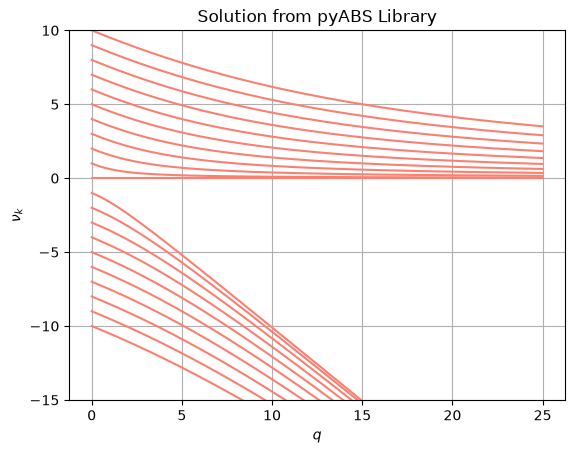

In [71]:
fig, ax = plt.subplots()
ax.set_ylim(-15,10)
#for i in range(len(modes)):
#    plt.scatter(sc, eigenscan[i])
plt.title("Solution from pyABS Library")
plt.grid()
plt.plot(sc, eigenscan_tracked, color='salmon')
ax.set_ylabel(r"$\nu_{k}$")
ax.set_xlabel(r"$q$")
plt.savefig("../../plots/pyabs_nowake.png", dpi=300)
plt.show()

compare with analytical solutions from burov
double check where the complex number went in burov

In [68]:
#analytic solutions
#analytic eigenvalues are given as
def real_eigen(n_max, q):
    modes = np.arange(-n_max, (n_max)+1, dtype=int)
    soln=[]
    for i in modes:
        if(i >= 0):
            soln.append(-q/2 + np.sqrt((q**2)/4 + i**2))
        if(i < 0):
            soln.append(-q/2 - np.sqrt((q**2)/4 + i**2))
    return soln

real_scan = []
#print(eigenscan_tracked)
analytical_solutions = []
for i, q in enumerate(sc):
    real_scan.append(real_eigen(n_max, q))
    


#print(eigenscan_tracked)
np.array(real_scan).shape

(600, 21)

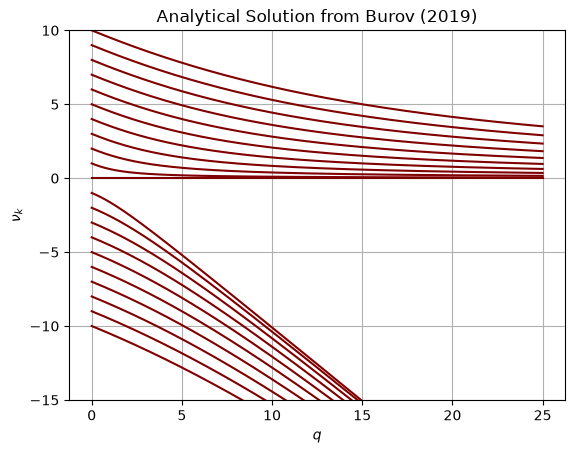

In [69]:
fig, ax = plt.subplots()
ax.set_ylim(-15,10)
plt.title("Analytical Solution from Burov (2019)")
plt.grid()
plt.plot(sc, real_scan, color='maroon')
ax.set_ylabel(r"$\nu_{k}$")
ax.set_xlabel(r"$q$")
plt.savefig("../../plots/analytical_nowake.png", dpi=300)
plt.show()

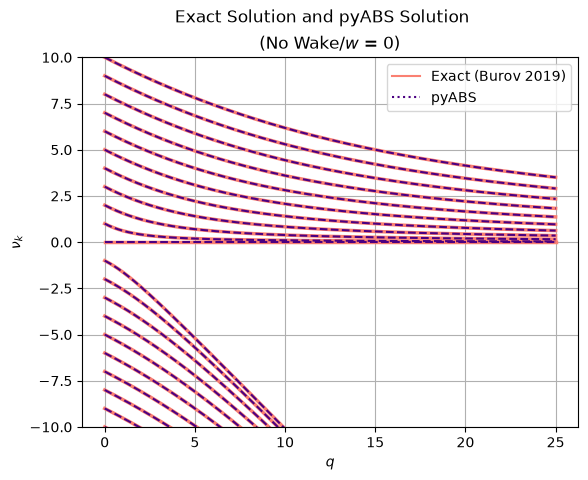

In [70]:
fig, ax = plt.subplots()
ax.set_ylim(-10,10)
plt.suptitle("Exact Solution and pyABS Solution")
plt.title(r"(No Wake/$w$ = 0)")
plt.grid()
plt.plot(sc, real_scan, color='salmon', lw=2.5)
plt.plot(sc, eigenscan_tracked, ls='--', color='indigo', lw = 1.5)
plt.plot([],[], color='salmon', label='Exact (Burov 2019)')
plt.plot([],[], ls=':',color='indigo', label="pyABS")
ax.legend()
ax.set_ylabel(r"$\nu_{k}$")
ax.set_xlabel(r"$q$")
plt.savefig("../../plots/overlay_nowake.png", dpi=300)
plt.show()